# Model validation

A low training loss says little: the model may have learned the noise of the
training data, or be right one step ahead and drift away over a longer horizon.
`validate` scores a trained model on data it has not seen, with the indicators
used in system identification, and draws the figures that show where it fails.

This tutorial shows:

- how `validate` scores every objective, and how to read its result;
- what each indicator means, for the whole signal and for each channel;
- the validation figures, and plots of your own;
- the validation of multi-step predictions (rollouts);
- how to look at the structure of a model with `export_html`.

In [1]:
import os

# Pick the Keras backend before nnodely (or Keras) is imported:
# "tensorflow" (the default), "torch" or "jax".
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

import tempfile
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, Image, display

from nnodely import (
    DataLoader,
    Fir,
    Input,
    Linear,
    Modely,
    ModelyLoop,
    Output,
    Parameter,
    Tanh,
    set_seed,
)

set_seed(0)
workdir = Path(tempfile.mkdtemp(prefix="nnodely_validation_"))

## A model to validate

A motor whose speed answers its voltage through a slow response and a
saturation. The model reads the last 20 samples of the voltage, filters them
with a `Fir`, and bends the result through a small network.

In [2]:
rng = np.random.default_rng(1)
T = 3000
voltage = np.repeat(rng.uniform(-2.0, 2.0, T // 40), 40)
response = np.convolve(voltage, np.exp(-np.arange(20) / 4.0) / 4.5)[:T]
speed = 3.0 * np.tanh(0.6 * response) + 0.03 * rng.standard_normal(T)

u = Input("voltage", tw=20)
filtered = Fir(features=4)([u])
predicted = Output("speed", Linear(features=1)([Tanh()(filtered)]))
motor = Modely("motor", inputs=[u], outputs=[predicted])
motor.minimize("speed_fit", predicted, Input("speed_meas", tw=1))
motor.build()

split = int(0.7 * T)
signals = {"voltage": voltage, "speed_meas": speed}
train_data = DataLoader(motor, source={k: v[:split] for k, v in signals.items()})
val_data = DataLoader(motor, source={k: v[split:] for k, v in signals.items()})
history = motor.train(
    train_data, val_data=val_data, epochs=40, batch_size=32, lr=1e-2, printer=None
)

## Scoring the model

`validate(val_data)` evaluates every objective of the model on the data, exactly
as training evaluates it - the same forward pass, the same alignment of the
target - and prints a summary:

In [3]:
result = motor.validate(val_data)

============================== nnodely Validation ==============================
Model:                        motor
Samples:                      881
Minimizers:                   1
--------------------------------------------------------------------------------
speed_fit   (speed vs speed_meas)
  Loss (mean_squared_error)     3.7122e-03
  Points scored                        881
  RMSE                          6.0928e-02
  MAE                           5.2291e-02
  Max error                     1.6866e-01
  Bias (mean error)            +2.4453e-02
  Error std                     5.5806e-02
  NRMSE (% of range)               1.218 %
  FIT                             96.304 %
  R2                              0.998634
  VAF                             99.885 %
  Correlation                     0.999795


The result holds a score per objective, picked by name (or by index, in the
order of `motor.minimizers`). `metrics` is a dict of the indicators, plain
numbers to log or compare; the result is the list of the scores, so
`{s.name: s.metrics for s in result}` gives every objective's at once:

In [4]:
score = result["speed_fit"]
print({name: round(float(value), 4) for name, value in score.metrics.items()})
print("points scored:", score.points)

{'loss': 0.0037, 'rmse': 0.0609, 'mae': 0.0523, 'max_error': 0.1687, 'bias': 0.0245, 'std_error': 0.0558, 'nrmse_pct': 1.2185, 'fit_pct': 96.3041, 'r2': 0.9986, 'vaf_pct': 99.8854, 'correlation': 0.9998, 'non_finite': 0.0}
points scored: 881


## What the indicators mean

With $e = \hat y - y$ the error between prediction and target:

| Indicator | Definition | Read it as |
|---|---|---|
| `loss` | the objective's training loss | comparable with `val_<name>_loss` of the history |
| `rmse`, `mae`, `max_error` | RMS, mean and peak of $\lvert e \rvert$ | errors in the units of the signal |
| `bias`, `std_error` | mean and standard deviation of $e$ | systematic and random error: $\mathrm{rmse}^2 = \mathrm{bias}^2 + \mathrm{std}^2$ |
| `nrmse_pct` | $100\,\mathrm{rmse} / \mathrm{range}(y)$ | the error relative to the span of the signal |
| `fit_pct` | $100\,(1 - \lVert e\rVert / \lVert y - \bar y\rVert)$ | the system-identification FIT: 100 perfect, 0 no better than the mean |
| `r2` | $1 - \sum e^2 / \sum (y - \bar y)^2$ | the coefficient of determination |
| `vaf_pct` | $100\,(1 - \mathrm{var}(e) / \mathrm{var}(y))$ | variance accounted for: R2 that forgives an offset |
| `correlation` | Pearson's correlation of $\hat y$ and $y$ | shape agreement, whatever the scale |
| `non_finite` | count of NaN / infinite errors | anything but 0 is a problem |

A signal of several features is scored **per channel**, each against its own
spread: a position in metres and a velocity in mm/s do not drown each other.
`channel_metrics` has one value per channel; the whole-signal values pool the
channels (absolute indicators) or average them (relative ones).

In [5]:
print(score.channel_metrics["fit_pct"], score.channel_metrics["rmse"])

[96.30411797] [0.06092808]


## Figures

With `out_dir`, `validate` saves a figure per objective - prediction against
target, the error, a parity plot and the error histogram - and, given the
training `history`, the loss curves. `result.figures` lists the files:

motor_speed_fit.png


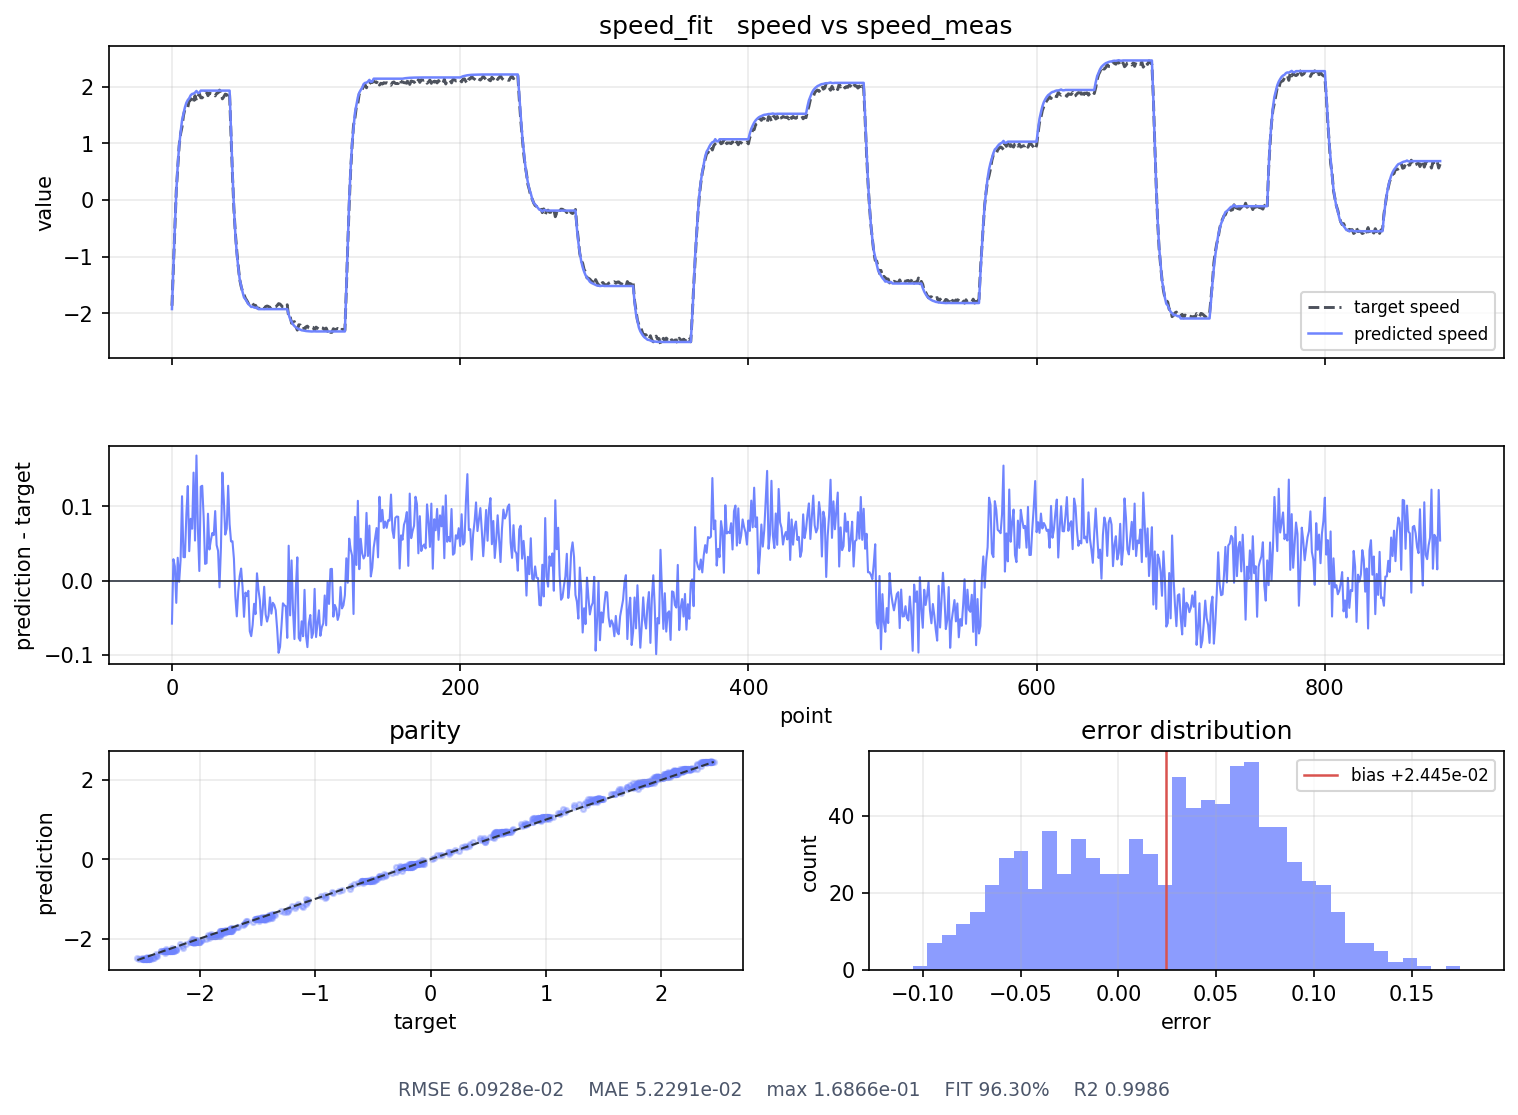

motor_history.png


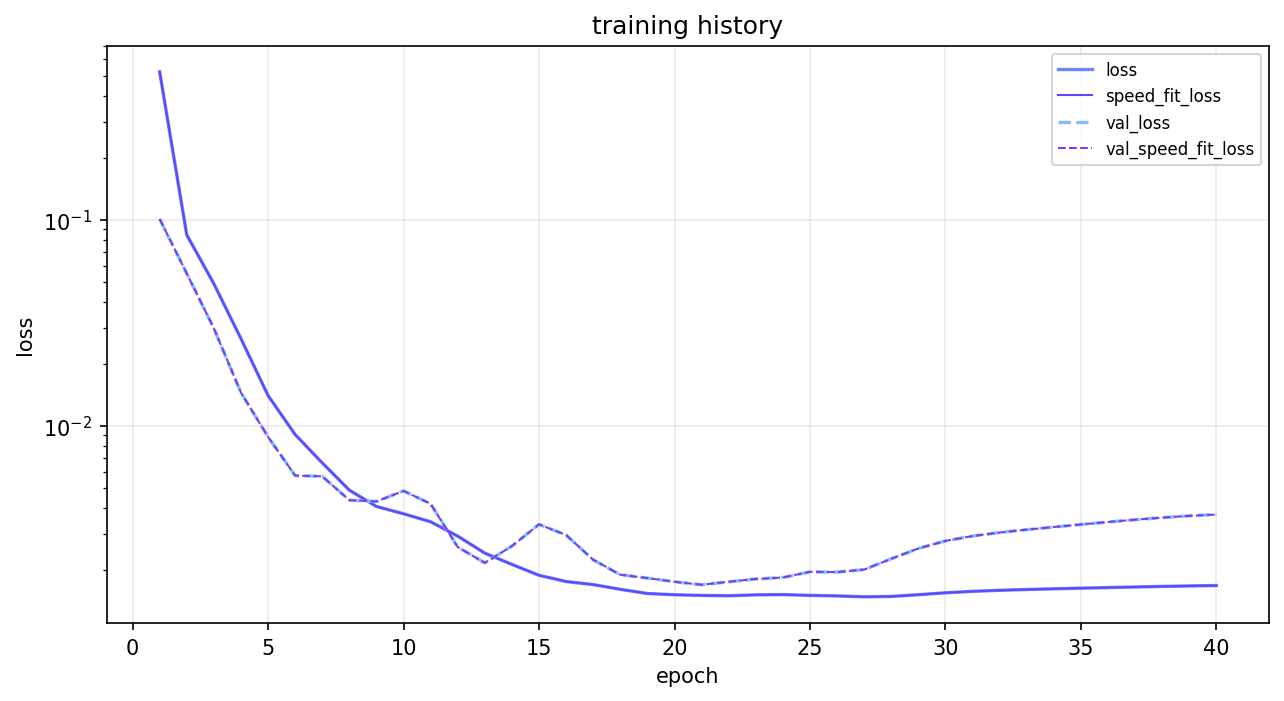

In [6]:
result = motor.validate(val_data, out_dir=workdir, history=history, verbose=False)
for figure in result.figures:
    print(Path(figure).name)
    display(Image(filename=figure, width=760))

The model output can also be computed and plotted directly: run it on the
validation samples, batched by `as_dict()`. The target is in the data too,
under its input name.

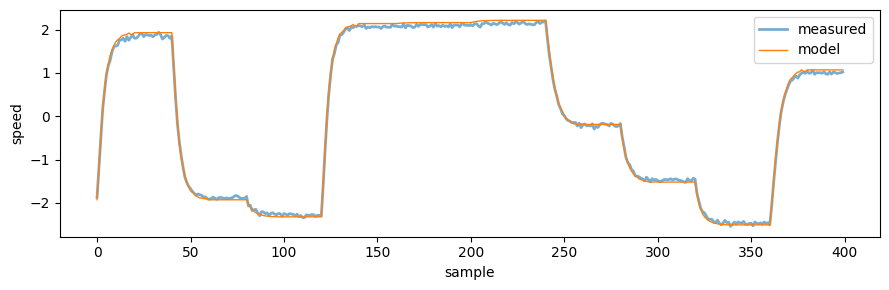

In [7]:
batch = val_data.as_dict()
prediction = keras.ops.convert_to_numpy(motor(batch)["speed"]).ravel()
measured = batch["speed_meas"].ravel()

plt.figure(figsize=(9, 3))
plt.plot(measured[:400], label="measured", lw=2, alpha=0.6)
plt.plot(prediction[:400], label="model", lw=1)
plt.xlabel("sample")
plt.ylabel("speed")
plt.legend()
plt.tight_layout()

## Validating a rollout

A one-step predictor is always corrected by the measured past; a simulator is
not, and its errors pile up along the horizon. A model that predicts several
steps ahead - here a `ModelyLoop`, see
[Recurrent models](10_recurrent_loop.ipynb) - is scored on every step of its
trajectories, and `step_rmse` shows how the error grows with the horizon.

The system is a first-order lag `x[k+1] = 0.9 x[k] + 0.2 u[k]`; the model starts
with wrong coefficients, and its state `x` is fed back from one step to the
next.

a = [0.8999621]  b = [0.20003608]


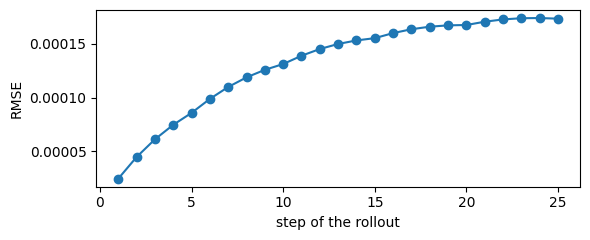

In [8]:
U = np.repeat(rng.uniform(-1.0, 1.0, 100), 30)
X = np.zeros(len(U))
for k in range(len(U) - 1):
    X[k + 1] = 0.9 * X[k] + 0.2 * U[k]

x, inp = Input("x", tw=1), Input("u", tw=1)
a, b = Parameter("a", value=0.5), Parameter("b", value=0.5)
x_next = x.feedback(a * x + b * inp)
lag = ModelyLoop("lag", inputs=[x, inp], outputs=[Output("x_next", x_next)])
lag.minimize("trajectory", "x_next", Input("x_meas", tw=1))
lag.build()

H = 25  # the horizon: samples of 25 steps
data = {"x": X[:-1], "u": U[:-1], "x_meas": X[1:]}
rollouts = DataLoader(lag, source=data, seq_length=H, step=5)
lag.train(rollouts, epochs=10, batch_size=32, lr=2e-2, printer=None)
print("a =", a.value_numpy, " b =", b.value_numpy)

rollout_result = lag.validate(rollouts, verbose=False)
step_rmse = rollout_result["trajectory"].step_rmse  # (steps, channels)
plt.figure(figsize=(6, 2.5))
plt.plot(np.arange(1, H + 1), step_rmse[:, 0], marker="o")
plt.xlabel("step of the rollout")
plt.ylabel("RMSE")
plt.tight_layout()

## The structure of a model

`export_html(folder)` draws the graph of a model as an interactive page: every
input, layer, parameter and output is a node, coloured by its role, and the
arrows carry the shapes. A model with blocks gets a page per block (double-click
a block to open it), plus a `<name>__flattened.html` page with every block
inlined. The legend under the graph highlights a role, and the panel searches
nodes and shows what a node depends on.

In [9]:
motor.export_html(workdir / "graph")
print(sorted(path.name for path in (workdir / "graph").iterdir()))

['imgs', 'motor.html', 'motor__flattened.html']


Open the page in a browser - or show it here, in the notebook. The page loads
its logo from the `imgs` folder next to it; the helper below puts the logo in
the page itself, so that it can be shown on its own:


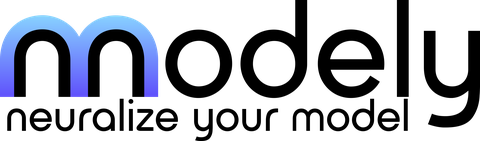

In [10]:
import base64
import html


def show_graph(page_path, height=520):
    """Show a page written by export_html inside the notebook."""
    page_path = Path(page_path)
    logo = page_path.parent / "imgs" / "logo_info.png"
    inline_logo = (
        "data:image/png;base64," + base64.b64encode(logo.read_bytes()).decode()
    )
    page = page_path.read_text().replace("imgs/logo_info.png", inline_logo)
    frame = f'<iframe srcdoc="{html.escape(page)}" style="width:100%; height:{height}px; border:0"></iframe>'
    return HTML(f"<div>{frame}</div>")


show_graph(workdir / "graph" / "motor.html")

The rollout model shows its state: the `x` input fed back with its next value
(teal arrow), and the loss comparing the trajectory with its target.


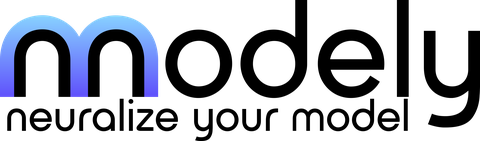

In [11]:
lag.export_html(workdir / "lag_graph")
show_graph(workdir / "lag_graph" / "lag.html")

## Summary

| Task | Code |
|---|---|
| Score every objective | `result = model.validate(val_data)` |
| One objective | `result["name"].metrics["fit_pct"]`, `.channel_metrics`, `.points` |
| Everything as numbers | `{s.name: s.metrics for s in result}` |
| Figures | `model.validate(val_data, out_dir="plots", history=history)`, `result.figures` |
| A rollout | `result["name"].step_rmse`, `(steps, channels)` |
| Own plots | `model(val_data.as_dict())`, converted with `keras.ops.convert_to_numpy` |
| The graph | `model.export_html("folder")` |

Next: [Save, load and export](05_save_load_export.ipynb).